In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


DATA_DIR = Path("C:\ML\data")

data_path = DATA_DIR / "diabetic_data.csv"
mapping_path = DATA_DIR / "IDS_mapping.csv"


df = pd.read_csv(data_path)
ids_mapping = pd.read_csv(mapping_path) if mapping_path.exists() else None

# The  dataset uses '?' as a missing-value marker.
df = df.replace("?", np.nan)

print("Main dataset shape:", df.shape)
if ids_mapping is not None:
    print("Mapping dataset shape:", ids_mapping.shape)
display(df.head())

Main dataset shape: (101766, 50)
Mapping dataset shape: (67, 2)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [2]:
print("DATASET SHAPE:", df.shape)
print("\nDATA TYPES")
display(df.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))
display(df.dtypes.rename("data_type").to_frame())

DATASET SHAPE: (101766, 50)

DATA TYPES


,column_count
dtype,
str,37
int64,13


,data_type
encounter_id,int64
patient_nbr,int64
race,str
gender,str
age,str
weight,str
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64


In [3]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_report = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})
display(missing_report)

,Missing Count,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [4]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate encounter IDs:", df["encounter_id"].duplicated().sum())
print("Repeated patient IDs:", df["patient_nbr"].duplicated().sum())

Exact duplicate rows: 0
Duplicate encounter IDs: 0
Repeated patient IDs: 30248


ORIGINAL READMISSION DISTRIBUTION


,Count
readmitted,
NO,54864
>30,35545
<30,11357


,Count,Percentage
readmitted_30d,,
0,90409,88.84
1,11357,11.16


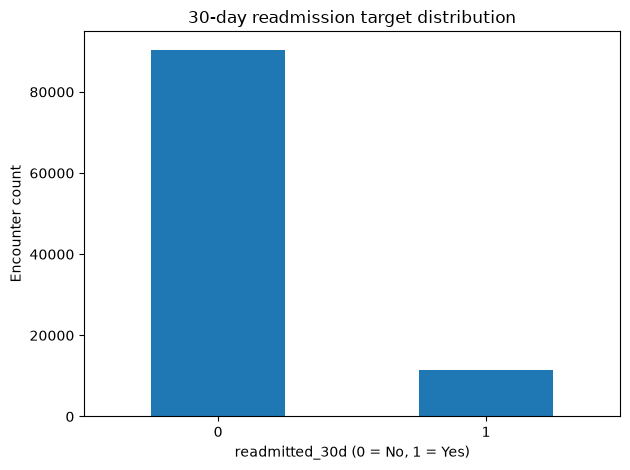

In [5]:
print("ORIGINAL READMISSION DISTRIBUTION")
display(df["readmitted"].value_counts(dropna=False).to_frame("Count"))

df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)

target_counts = df["readmitted_30d"].value_counts().sort_index()
target_percentages = (
    df["readmitted_30d"].value_counts(normalize=True).sort_index() * 100
)

target_report = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})
display(target_report)

ax = target_counts.plot(kind="bar", rot=0, title="30-day readmission target distribution")
ax.set_xlabel("readmitted_30d (0 = No, 1 = Yes)")
ax.set_ylabel("Encounter count")
plt.tight_layout()
plt.show()

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns
excluded_from_outlier_check = {
    "encounter_id", "patient_nbr", "readmitted_30d",
    "admission_type_id", "discharge_disposition_id", "admission_source_id"
}

outlier_results = []
for col in numeric_cols:
    if col in excluded_from_outlier_check:
        continue

    values = df[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    if iqr > 0:
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = ((values < lower) | (values > upper)).sum()
        outlier_results.append({
            "Feature": col,
            "Lower Fence": lower,
            "Upper Fence": upper,
            "Potential Outliers": int(count)
        })

outlier_df = pd.DataFrame(outlier_results)
if not outlier_df.empty:
    outlier_df = outlier_df.sort_values("Potential Outliers", ascending=False)
display(outlier_df)

,Feature,Lower Fence,Upper Fence,Potential Outliers
4,number_inpatient,-1.5,2.5,7049
2,num_procedures,-3.0,5.0,4954
3,num_medications,-5.0,35.0,2557
0,time_in_hospital,-4.0,12.0,2252
5,number_diagnoses,1.5,13.5,281
1,num_lab_procedures,-8.0,96.0,143
